# Разностные уравнения и метод Ньютона

**Задача 2.1.** Новорожденная пара кроликов два месяца не рожает, на третий рожает \(m\) пар, на четвёртый — \(k\) пар, во все последующие — по одной.
Нужно написать конечно-разностное уравнение, описывающее эту динамику. Построить характеристический многочлен, построить его график и найти все его корни методом Ньютона. Какой из корней отвечает за рост решения спустя много месяцев?

Муравьёв Герман

In [21]:
import numpy as np
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = 'retina'

# Постоянные
m = 2
k = 17

# Палитра
dark_purple = [0.2980, 0.1373, 0.3961] # вещественная часть / основной график
red         = [0.7529, 0.4235, 0.5176] # мнимая часть / вспомогательные линии
mauve       = [0.6196, 0.4941, 0.7098] # сетка

## Решение

Для начала составим уравнение, отсчитыем месяцы от рождения первой пары, где $n=0$ – начальный момент. Первые рождения происходят при $n=3$.
Обозначим через $x(n)$ число пар кроликов, родившихся в месяце $n$. Начальную пару учитываем как $x(0)=1$. Тогда
$$
x(1)=x(2)=0,\qquad x(3)=m,\qquad x(4)=k.
$$

В месяце $n$ возраст трёх месяцев имеют пары, родившиеся в месяце $n-3$. Их число равняется $x(n-3)$, и каждая рожает $m$ новых пар. Вместе они рожают $m \times x(n-3)$ пар. Аналогично пары возраста четырёх месяцев рожают $k \times x(n-4)$ пар. Каждая более старая пара рожает одну пару. Поэтому при $n\geq5$
имеем:
$$
x(n)=m x(n-3)+k x(n-4)+\sum_{j=0}^{n-5}x(j).
$$

Для предыдущего месяца:
$$
x(n-1)=m x(n-4)+k x(n-5)+\sum_{j=0}^{n-6}x(j).
$$

При $n=5$ последняя сумма пустая и равна нулю. Вычитаем второе равенство из первого:
$$
x(n)-x(n-1)=m(x(n-3)-x(n-4))+k(x(n-4)-x(n-5))+x(n-5).
$$

Раскрываем скобки и переносим слагаемые влево:
$$
x(n)-x(n-1)=mx(n-3)-mx(n-4)+kx(n-4)-kx(n-5)+x(n-5).
$$

Приводим подобные слагаемые:
$$
x(n)-x(n-1)=mx(n-3)+(k-m)x(n-4)+(1-k)x(n-5).
$$

Переносим все слагаемые в левую часть:
$$
x(n)-x(n-1)-mx(n-3)+(m-k)x(n-4)+(k-1)x(n-5)=0,\qquad n\geq5.
$$

Это линейное однородное конечно-разностное уравнение пятого порядка с постоянными коэффициентами.

При $m=2$, $k=17$ получаем:
$$
x(n)=x(n-1)+2x(n-3)+15x(n-4)-16x(n-5),\qquad n\geq5.
$$

Начальные условия:
$$
x(0)=1,\quad x(1)=x(2)=0,\quad x(3)=2,\quad x(4)=17.
$$

Вычислим первые значения по полученному уравнению.

In [22]:
months = 80

x = [1, 0, 0, m, k]
for n in range(5, months + 1):
    x.append(x[n - 1] + m * x[n - 3] + (k - m) * x[n - 4] + (1 - k) * x[n - 5])

print('Месяц n    Число родившихся пар x(n)')

for n in range(11):
    print(f'{n:7d} {x[n]:28d}')


Месяц n    Число родившихся пар x(n)
      0                            1
      1                            0
      2                            0
      3                            2
      4                           17
      5                            1
      6                            5
      7                           69
      8                          294
      9                           47
     10                          244


##### Строим характеристический многочлен
Будем искать решение в виде $x(n)=As^n$, $A\ne0$, $s\ne0$. При подстановке в разностное уравнение получаем уравнение характеристическое:
$$
s^k+a_1s^{k-1}+\ldots+a_k=0.
$$

Подставим $x(n)=As^n$ в уравнение нашего задания:
$$
As^n-As^{n-1}-mAs^{n-3}+(m-k)As^{n-4}+(k-1)As^{n-5}=0.
$$

Разделим на $As^{n-5}$:
$$
s^5-s^4-ms^2+(m-k)s+(k-1)=0.
$$

Следовательно,
$$
P(s)=s^5-s^4-ms^2+(m-k)s+(k-1).
$$

Для нашего варианта
$$
P(s)=s^5-s^4-2s^2-15s+16.
$$

Нулевой корень при делении не потерян, так как $P(0)=16\ne0$.

##### Выбираем отрезок для графика

Рассмотрим полученный многочлен:
$$
P(s)=s^5-s^4-2s^2-15s+16.
$$

Сначала нужно определить, в какой области могут находиться его корни. Для этого используем оценку Коши:
$$
|s|\leq 1+\max_{0\leq j<n}\left|\frac{a_j}{a_n}\right|,
$$

где $a_n$ – коэффициент при старшей степени, а $a_j$ – остальные коэффициенты.
В нашем многочлене старшая степень равна пяти. Выпишем все коэффициенты, включая нулевой коэффициент при $s^3$:
$$
a_5=1,\quad a_4=-1,\quad a_3=0,\quad a_2=-2,\quad a_1=-15,\quad a_0=16.
$$

Разделим остальные коэффициенты на старший коэффициент $a_5=1$ и возьмём модули:
$$
\left|\frac{-1}{1}\right|=1,\quad
\left|\frac{0}{1}\right|=0,\quad
\left|\frac{-2}{1}\right|=2,\quad
\left|\frac{-15}{1}\right|=15,\quad
\left|\frac{16}{1}\right|=16.
$$

Наибольшее значение равно $16$. Следовательно,
$$
|s|\leq 1+16=17.
$$

Это означает, что все комплексные корни находятся в круге с центром в нуле и радиусом $17$. Для вещественных корней условие $|s|\leq17$ означает:
$$
-17\leq s\leq17.
$$

Поэтому сначала строим график $P(s)$ на отрезке $-17,17$. Вещественные корни – это точки, в которых график пересекает горизонтальную ось.

В ходе построение было выявлена, что на таком большом отрезке пересечения плохо различимы: вдали от нуля значения $s^5$ становятся очень большими. Поэтому дополнительно увеличиваем участок $-3,3$. Число $3$ не получено из оценки Коши: этот участок выбран для более подробного изображения корней.


Оценка Коши: все корни лежат в круге |s| ≤ 17


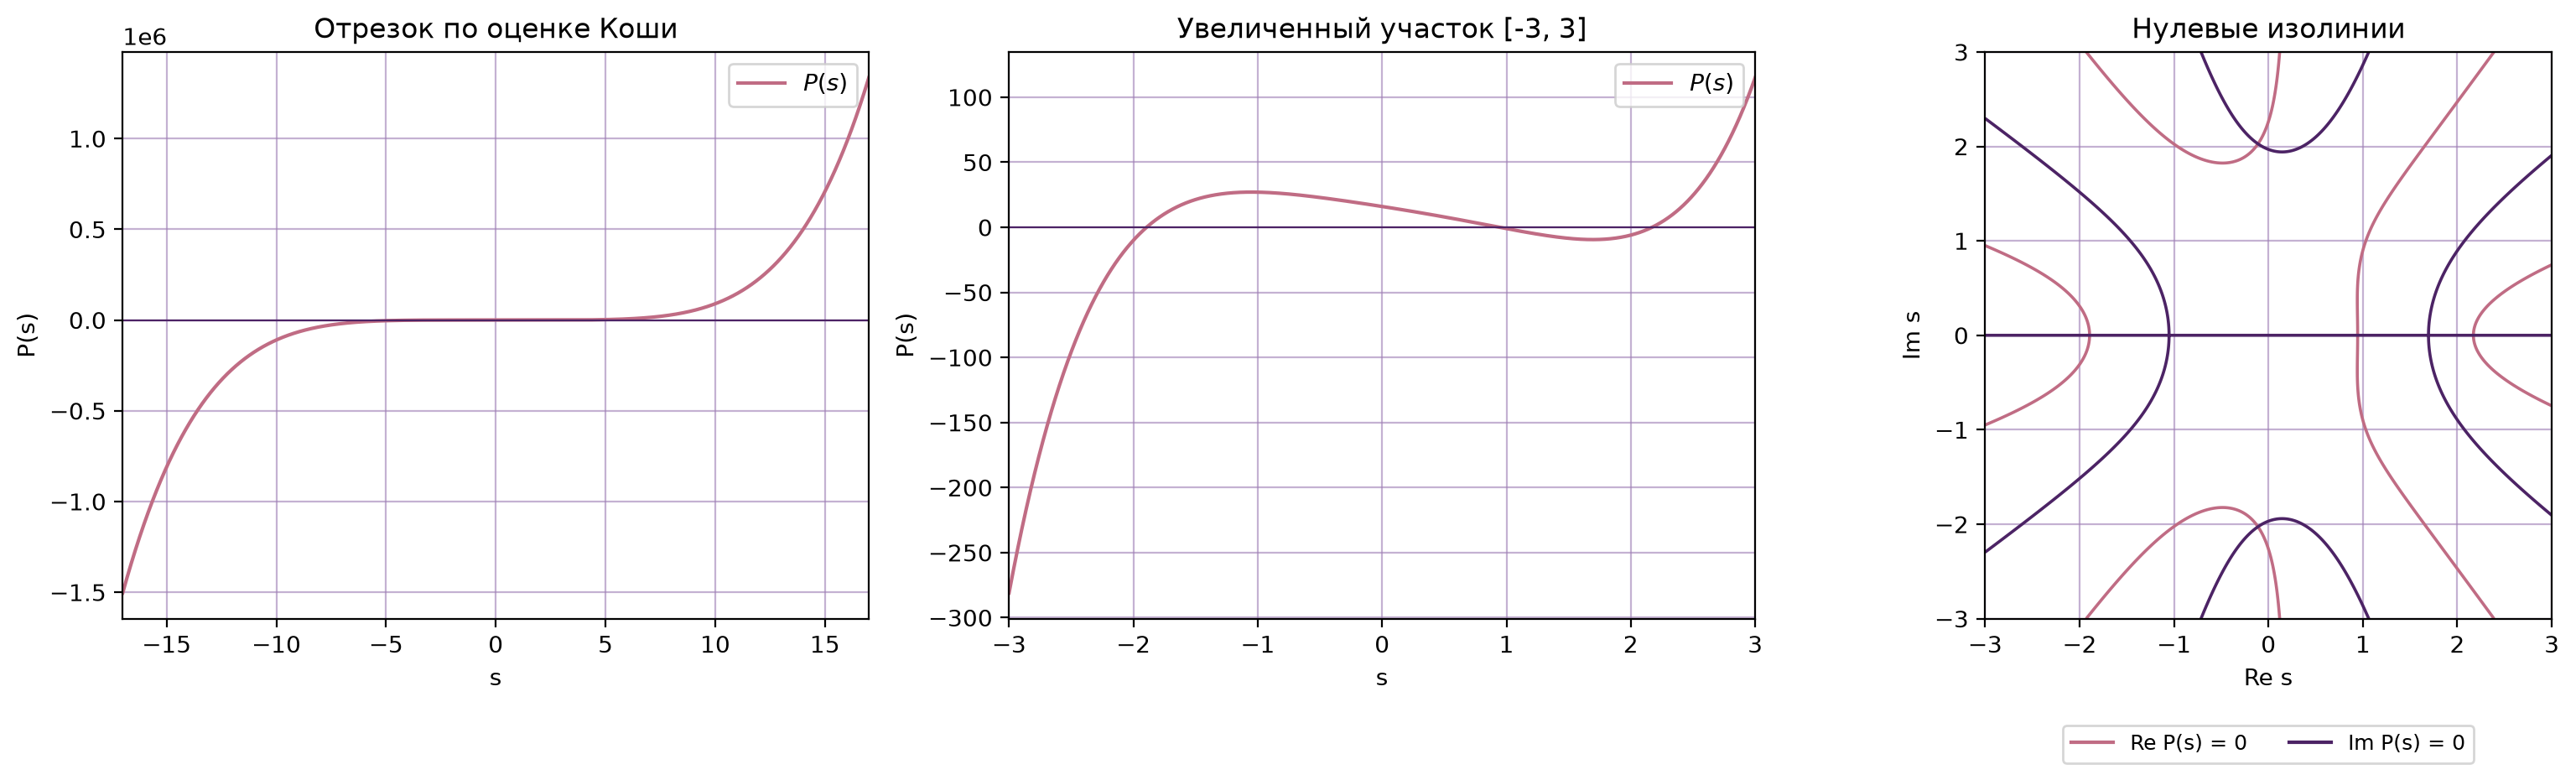

In [18]:
def P(s):
    return s**5 - s**4 - m * s**2 + (m - k) * s + k - 1


def dP(s):
    return 5 * s**4 - 4 * s**3 - 2 * m * s + m - k


coef = np.array([1, -1, 0, -m, m - k, k - 1])
R = 1 + np.max(np.abs(coef[1:] / coef[0]))

print(f'Оценка Коши: все корни лежат в круге |s| ≤ {R:g}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), facecolor='white')

for ax in axes:
    ax.set_facecolor('white')
    ax.grid(color=mauve, alpha=0.6)

for ax, bound in zip(axes[:2], [R, 3]):
    s = np.linspace(-bound, bound, 6001)
    ax.plot(s, P(s), color=red, label=r'$P(s)$')
    ax.axhline(0, color=dark_purple, lw=0.8)
    ax.set(xlabel='s', ylabel='P(s)', xlim=(-bound, bound))
    ax.legend()

axes[0].set_title('Отрезок по оценке Коши')
axes[1].set_title('Увеличенный участок [-3, 3]')

real = np.linspace(-3, 3, 601)
imaginary = np.linspace(-3, 3, 601)

X, Y = np.meshgrid(real, imaginary)
Z = X + 1j * Y

axes[2].contour(X, Y, P(Z).real, levels=[0], colors=[red], linewidths=1.3)
axes[2].contour(X, Y, P(Z).imag, levels=[0], colors=[dark_purple], linewidths=1.3)
axes[2].plot([], [], color=red, label='Re P(s) = 0')
axes[2].plot([], [], color=dark_purple, label='Im P(s) = 0')
axes[2].set(xlabel='Re s', ylabel='Im s', title='Нулевые изолинии')
axes[2].set_aspect('equal')
axes[2].legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.17),
    ncol=2,
    fontsize=9,
)

plt.tight_layout()
plt.show()


##### Находим корни методом Ньютона

Допустим, мы можем вычислить значение гладкой функции $f(x)$ и её производной в любой точке. Нужно найти корень функции, то есть такое $x$, при котором $f(x) = 0$.
Работать напрямую со сложной функцией трудно, поэтому заменим её чем-то простым. Выберем начальную точку $x_1$ и вместо самой кривой возьмём касательную к ней в этой точке. Вблизи $x_1$ касательная почти совпадает с графиком функции, а корень прямой найти легко: нужно решить линейное уравнение.
Уравнение касательной (линейное приближение функции):
$$
N(x)=f(x_1)+f'(x_1)(x-x_1).
$$
Приравняв $N(x) = 0$, получаем корень касательной:
$$
x_2=x_1-\frac{f(x_1)}{f'(x_1)}.
$$

Точка $x_2$, как правило, ближе к настоящему корню, чем $x_1$. Повторим ту же процедуру, построив касательную уже в точке $x_2$:
$$
x_3=x_2-\frac{f(x_2)}{f'(x_2)}.
$$

Так можно продолжать дальше, пока не будет достигнута нужная точность. В общем виде:
$$
x_{n+1}=x_n-\frac{f(x_n)}{f'(x_n)}.
$$
$$
x_3=x_2-\frac{f(x_2)}{f'(x_2)}.
$$

Запишем отображение Ньютона:
$$
G(x)=x-\frac{f(x)}{f'(x)},\qquad x_{n+1}=x_n-\frac{f(x_n)}{f'(x_n)}.
$$

Здесь $x_n$ – приближение к корню; это не последовательность рождений $x(n)$ из первой части решения.
Применим эту формулу к $f=P$. Приближения к корню многочлена обозначим $s_j$. Линейное приближение в текущей точке:
$$
P(s)\approx P(s_j)+P'(s_j)(s-s_j).
$$

Приравниваем это выражение к нулю и получаем следующее приближение:
$$
s_{j+1}=s_j-\frac{P(s_j)}{P'(s_j)}.
$$

В нашем случае
$$
P'(s)=5s^4-4s^3-4s-15,
$$
$$
s_{j+1}=s_j-\frac{s_j^5-s_j^4-2s_j^2-15s_j+16}{5s_j^4-4s_j^3-4s_j-15}.
$$

На вещественном графике видны три пересечения. Для них выберем начальные точки $-2$, $0.8$, $2$. Но степень многочлена равна пяти, и сам вещественный график не показывает комплексные корни. На рисунке нулевых изолиний видны также пересечения около $2i$ и $-2i$. Поэтому для комплексных корней возьмём эти начальные приближения.
Останавливаем итерации, когда одновременно $|P(s_{j+1})|<10^{-11}$ и $|s_{j+1}-s_j|<10^{-12}$. Ограничение в 100 итераций и проверка знаменателя позволяют заметить неудачный выбор начальной точки. Сходимость метода не гарантирована для любой начальной точки. Исследуем неподвижную точку $x_*$ отображения $G$ и вычисляем ее по формуле:
$$
G'(x)=1-\frac{(f'(x))^2-f(x)f''(x)}{(f'(x))^2}.
$$

При $f(x_*)=0$ и $f'(x_*)\ne0$ получаем $G'(x_*)=0$ — в лекции это названо «сверхсжатие». Рассуждение относится к начальным приближениям, достаточно близким к корню. Для нашего многочлена проверяем значения $P$ и $P'$ в найденных точках.

In [23]:
def newton(z0, tol_f=1e-11, tol_x=1e-12, max_iter=100):
    z = complex(z0)
    history = [z]

    for iteration in range(1, max_iter + 1):
        derivative = dP(z)
        if abs(derivative) < 1e-14:
            raise ArithmeticError('Производная слишком близка к нулю')

        z_new = z - P(z) / derivative
        history.append(z_new)

        if abs(P(z_new)) < tol_f and abs(z_new - z) < tol_x:
            return z_new, history

        z = z_new

    raise ArithmeticError('Метод не сошёлся за заданное число итераций')


starts = [-2, 0.8, 2, 2j, -2j]
roots, histories = [], []

print('Начальная точка        Корень                              |s|          |P(s)|    Итерации')

for z0 in starts:
    root, history = newton(z0)
    roots.append(root)
    histories.append(history)

    print(
        f'{str(z0):>14}   {root.real: .10f}{root.imag:+.10f}i'
        f'    {abs(root):.10f}   {abs(P(root)):.2e}     {len(history) - 1:2d}'
    )

roots = np.array(roots)

# Проверяем, что найдены пять различных простых корней.
assert all(abs(roots[i] - roots[j]) > 1e-6 for i in range(5) for j in range(i))
assert np.max(np.abs(P(roots))) < 1e-11
assert np.min(np.abs(dP(roots))) > 1e-6

# По найденным корням восстанавливаем коэффициенты, как в лекции о многочленах.
coefficients = np.array([1, -1, 0, -m, m - k, k - 1])
coefficient_error = np.max(np.abs(np.poly(roots) - coefficients))

print(f'Ошибка восстановления коэффициентов: {coefficient_error:.2e}')
assert coefficient_error < 1e-10

print()
print('Итерации для положительного растущего корня:')

for j, z in enumerate(histories[2]):
    print(f'{j:2d}: s = {z.real:.12f}; |P(s)| = {abs(P(z)):.3e}')


Начальная точка        Корень                              |s|          |P(s)|    Итерации
            -2   -1.8939378920+0.0000000000i    1.8939378920   1.42e-14      5
           0.8    0.9447296330+0.0000000000i    0.9447296330   0.00e+00      4
             2    2.1705290888+0.0000000000i    2.1705290888   1.07e-14      6
            2j   -0.1106604149+2.0267218357i    2.0297406550   1.28e-14      5
       (-0-2j)   -0.1106604149-2.0267218357i    2.0297406550   1.28e-14      5
Ошибка восстановления коэффициентов: 7.11e-15

Итерации для положительного растущего корня:
 0: s = 2.000000000000; |P(s)| = 6.000e+00
 1: s = 2.240000000000; |P(s)| = 3.583e+00
 2: s = 2.177093017304; |P(s)| = 3.076e-01
 3: s = 2.170595067123; |P(s)| = 3.061e-03
 4: s = 2.170529095560; |P(s)| = 3.133e-07
 5: s = 2.170529088805; |P(s)| = 1.066e-14
 6: s = 2.170529088805; |P(s)| = 1.066e-14


Получили три вещественных корня и два комплексно-сопряжённых:
$$
s_1\approx-1.8939378920,\qquad s_2\approx0.9447296330,\qquad s_3\approx2.1705290888,
$$
$$s_{4,5}\approx-0.1106604149\pm2.0267218357i.
$$

Все пять значений различны, невязки малы, производная в них не равна нулю.
Многочлен представляется в виде:
$$
P_n(x)=a_0x^n+a_1x^{n-1}+\ldots+a_n=a_0(x-x_1)\cdots(x-x_n).
$$

Многочлен пятой степени не может иметь больше пяти различных корней. Восстановление коэффициентов дополнительно проверяет вычисления.

Найдем какой корень определяет рост
Если все корни характеристического уравнения разные (простые), то общее решение конечно-разностного уравнения $k$-ого порядка:
$$
x(n)=\sum_{j=1}^{k}A_js_j^n.
$$
Если корень кратный, то еще есть решения $x(n)=B\cdot n\cdot s^n$, если кратность равняется двум.

В нашем многочлене найдены пять различных корней, поэтому используем первую формулу:
$$
x(n)=A_1s_1^n+A_2s_2^n+A_3s_3^n+A_4s_4^n+A_5s_5^n.
$$
Для уравнения пятого порядка нужно задать пять начальных условий: $x(0)$, $x(1)$, $x(2)$, $x(3)$ и $x(4)$. Выполним тот же шаг для пяти корней:
$$
A_1+A_2+A_3+A_4+A_5=1.
$$
$$
A_1s_1+A_2s_2+A_3s_3+A_4s_4+A_5s_5=0.
$$
$$
A_1s_1^2+A_2s_2^2+A_3s_3^2+A_4s_4^2+A_5s_5^2=0.
$$
$$
A_1s_1^3+A_2s_2^3+A_3s_3^3+A_4s_4^3+A_5s_5^3=2.
$$
$$
A_1s_1^4+A_2s_2^4+A_3s_3^4+A_4s_4^4+A_5s_5^4=17.
$$

При больших $n$ первое слагаемое большое, а второе маленькое.

Далее в разобранном примере сравниваются модули корней. Применим это рассуждение к пяти слагаемым нашего решения. Сравниваем модули найденных корней:
$|s_2|<|s_1|<|s_4|=|s_5|\approx2.0297406550<s_3\approx2.1705290888.$
Поэтому, если $A_3\ne0$, после деления на $s_3^n$ все остальные слагаемые стремятся к нулю. Проверим коэффициент $A_3$ численно.

Наибольший модуль: rho = 2.170529088805
Коэффициент: C = 0.258011924311
Асимптотический прирост за месяц: 117.0529%


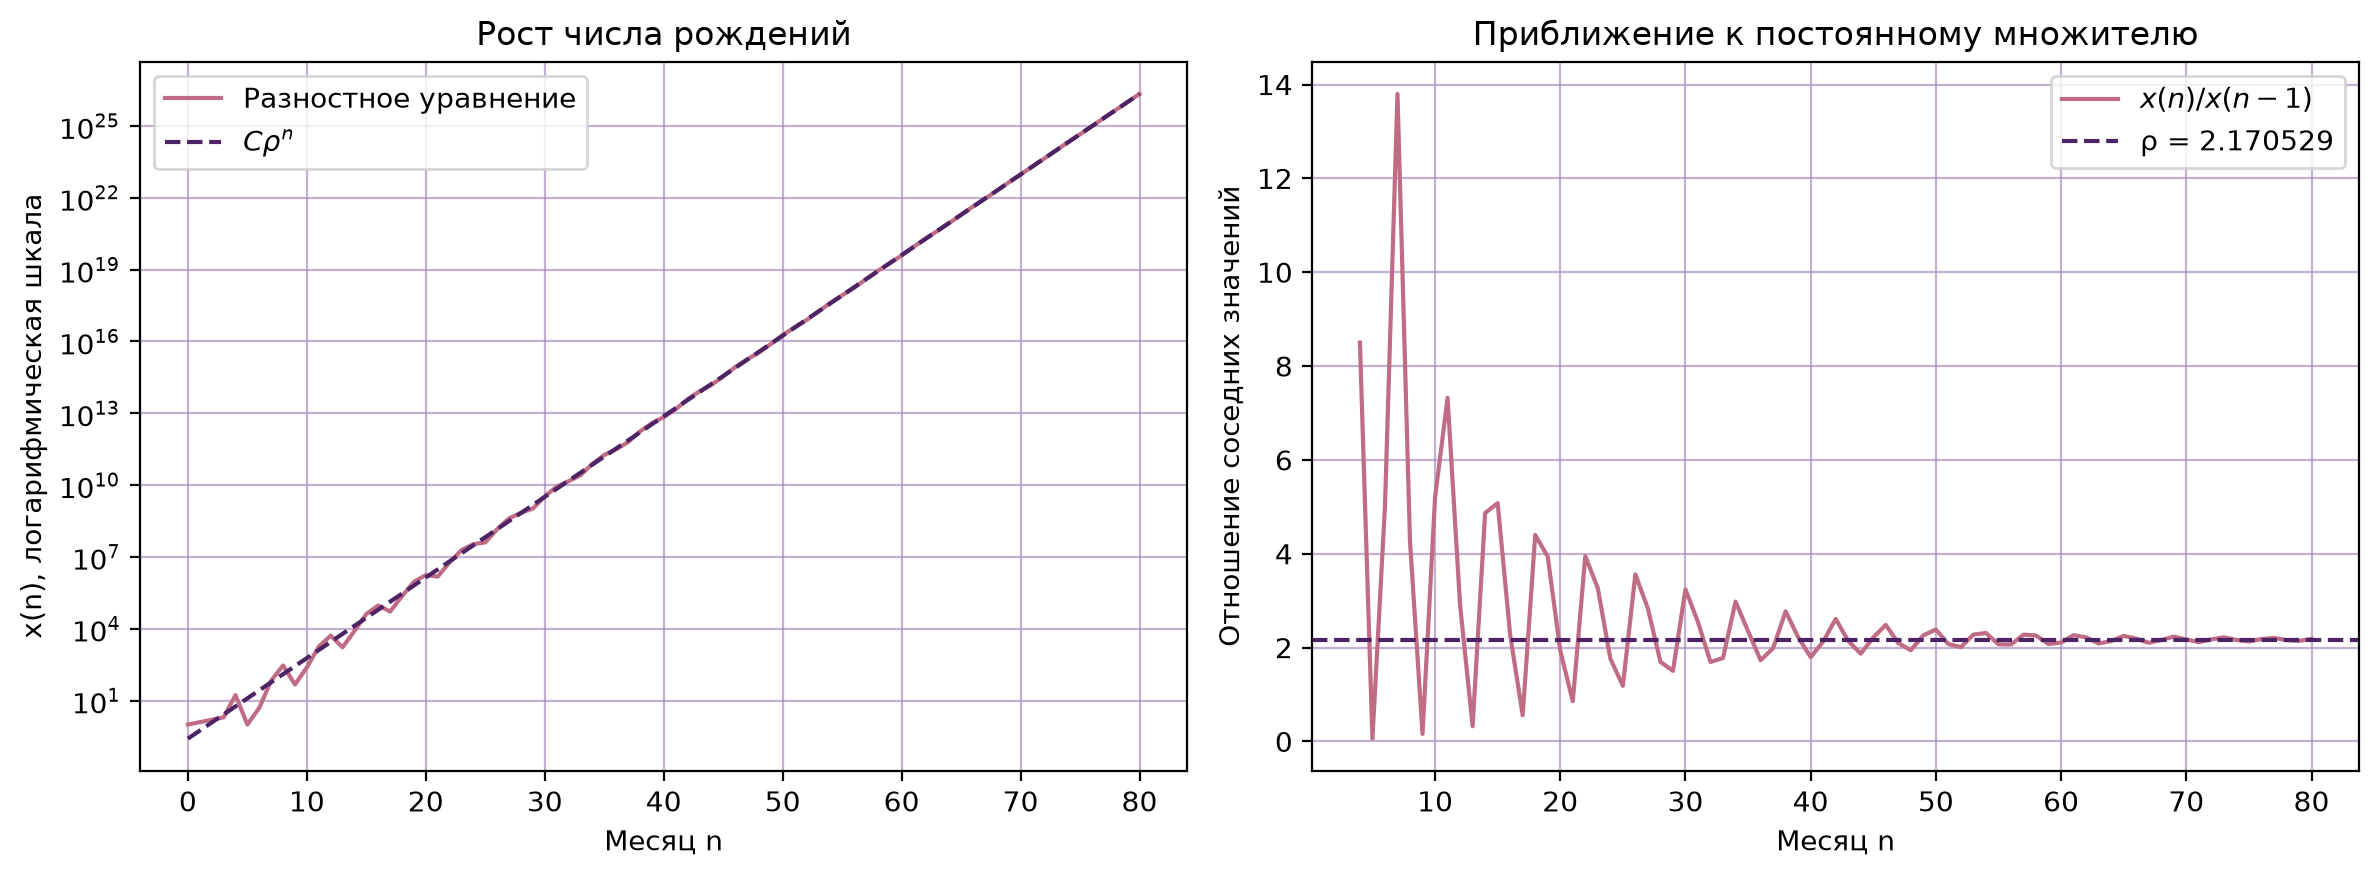

n=20: x(n)/rho**n = 0.327074817; x(n)/x(n-1) = 1.936385868
n=40: x(n)/rho**n = 0.237415420; x(n)/x(n-1) = 1.795233144
n=60: x(n)/rho**n = 0.249185838; x(n)/x(n-1) = 2.107836570
n=80: x(n)/rho**n = 0.257346345; x(n)/x(n-1) = 2.185194138


In [24]:
V = roots[None, :] ** np.arange(5)[:, None]
initial = np.array([1, 0, 0, m, k], dtype=float)
A = np.linalg.solve(V, initial)
dominant_index = np.argmax(np.abs(roots))
rho = roots[dominant_index].real
C = A[dominant_index].real

print(f'Наибольший модуль: rho = {rho:.12f}')
print(f'Коэффициент: C = {C:.12f}')
print(f'Асимптотический прирост за месяц: {(rho - 1) * 100:.4f}%')

assert C > 0

n = np.arange(months + 1)
x_values = np.array(x, dtype=float)
from_roots = (roots[None, :] ** n[:, None]) @ A

assert np.max(np.abs(from_roots - x_values) / np.maximum(1, x_values)) < 1e-10

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), facecolor='white')

for ax in axes:
    ax.set_facecolor('white')
    ax.grid(color=mauve, alpha=0.6)
axes[0].semilogy(
    n[x_values > 0],
    x_values[x_values > 0],
    color=red,
    label='Разностное уравнение',
)
axes[0].semilogy(n, C * rho**n, '--', color=dark_purple, label=r'$C\rho^n$')
axes[0].set(
    xlabel='Месяц n',
    ylabel='x(n), логарифмическая шкала',
    title='Рост числа рождений',
)
axes[0].legend()

axes[1].plot(
    n[4:],
    x_values[4:] / x_values[3:-1],
    color=red,
    label=r'$x(n)/x(n-1)$',
)
axes[1].axhline(rho, color=dark_purple, ls='--', label=f'ρ = {rho:.6f}')
axes[1].set(
    xlabel='Месяц n',
    ylabel='Отношение соседних значений',
    title='Приближение к постоянному множителю',
)
axes[1].legend()

plt.tight_layout()
plt.show()

for month in [20, 40, 60, 80]:
    print(
        f'n={month:2d}: x(n)/rho**n = {x_values[month] / rho**month:.9f}; '
        f'x(n)/x(n-1) = {x_values[month] / x_values[month - 1]:.9f}'
    )


Среди найденных корней наибольший модуль имеет положительный корень
$$
s_3\approx2.1705290888.
$$
Поэтому при больших $n$ слагаемое $A_3s_3^n$ определяет рост решения, а слагаемые, отвечающие корням меньшего модуля, дают меньший вклад. Следовательно, за рост решения спустя много месяцев отвечает корень $s_3$.